# When Nvidia Moves, Who Follows?

## Is AI exposure visible on paper or in stock prices?

### Research Question

Do firms identified as AI-exposed through their sector, R&D spending,
or membership in thematic ETFs also display greater sensitivity to
Nvidia's earnings announcements?

Does this relationship extend to international equity markets?

### Research Period
2018–2026
### Authors
Estelle Aoun & Aya Rhazi

## 1.Hypotheses and research design
**H1:** Firms' abnormal returns have very different sensitivities to Nvidia. A minority responds especially strongly

**H2:** Sector, R&D/revenue and thematic ETF labels are associated with these sensitivities, conditional on the available controls

**H3:** Sensitivities are higher after 30 November 2022 (ChatGPT's launch)

**H4:** Country-level exposure differs across stock markets and correlates with technological specialization and semiconductor trade links

An announcement occurring **after 16:00 US Eastern** is assigned to the **following US trading session**: the reaction is the close-to-close return from the announcement day's close to that next close. This is appropriate for US equities and the **US-listed country ETFs** used below. It is **not** a local-exchange-hours event study.

We use an estimation window of $[-250,-30]$ trading days to capture roughly one full trading year of baseline market behavior while stopping 30 days ahead of the release to prevent pre-announcement drift or information leaks from biasing our benchmark.
For each asset $i$ and earnings event $e$, estimate the market model over trading sessions $[-250,-30]$ relative to the first post-announcement session :

$$R_{i,t}=\alpha_{i,e}+\beta_{i,e}R_{m,t}+\varepsilon_{i,t}.$$

Then measure abnormal returns at the event:

$$AR_{i,e}=R_{i,e}-(\hat\alpha_{i,e}+\hat\beta_{i,e}R_{m,e}).$$

Finally, across earnings announcements, estimate the **revealed exposure** slope:

$$AR_{i,e}=a_i+b_i AR_{\mathrm{NVDA},e}+u_{i,e}.$$

A positive $b_i$ indicates directional co-movement; it is **not** a causal effect and is **not** the firm's ordinary market beta.

In [2]:
from pathlib import Path
import os
import sys

import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image, IFrame

#Ensure the project root is in sys.path so our custom 'src' modules import cleanly
ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

#Import custom data-loading, econometric and visualization functions from src/
from src.settings import Settings, CONFIG, PROCESSED, FIGURES
from src.analysis import (
    load_prices, check_events, event_session, data_quality, event_study,
    attach_nvda_shocks, sensitivity_by_stock, pre_post_sensitivity,
    market_betas_before_cutoff, cross_section_regression, country_regression,
    yearly_pca, placebo_nvda_shocks,
)
from src.plots import (
    plot_nvda_reactions, plot_sensitivity_distribution, plot_pre_post,
    plot_pca, plot_country_map, plot_country_two_periods,
)

#Initialize project paths and make sure output directories exist
settings = Settings()
DATA_ROOT = Path(os.environ.get("NVIDIA_PROJECT_DATA_DIR", ROOT / "data" / "raw"))
PROCESSED.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

#Configure pandas display so summary tables show enough columns cleanly
pd.set_option("display.max_columns", 15)
print("Working with data from:", DATA_ROOT)

Working with data from: c:\Users\alexi\ai-exposure-financial-markets\data\raw


## 2. Data collection, cleaning and quality checks

**Data pipeline and sources:** We combine multi-source public financial datasets stored as raw CSV snapshots in `data/raw/`, which are subsequently validated, aligned on US trading calendars, and joined by ticker and date. Baseline equity prices (Nvidia, Nasdaq-100 constituents, `SPY`/`QQQ` benchmarks, and 29 US-listed country ETFs) and earnings dates are collected via `python -m src.collect`. Firm-level R&D expenditures, revenues, and thematic ETF memberships are retrieved separately via `python -m src.firm_data` (using a compliant `SEC_USER_AGENT` header for SEC EDGAR access). Throughout the cleaning pipeline, missing observations are explicitly preserved as `NaN` rather than imputed with zeros, and missing ETF files are never treated as evidence of non-membership.

**Reproducibility:** All raw snapshots, automated validation checks, and collection scripts are versioned and documented in `README.md` so the full dataset can be regenerated from scratch.

In [5]:
#first we verify all raw prices and constituent files exist locally before loading them
required = ["us_prices.csv", "country_etf_prices.csv", "nasdaq100_constituents.csv"]
missing = [filename for filename in required if not (DATA_ROOT / filename).exists()]
if missing:
    raise FileNotFoundError(
        "Missing source snapshots: " + ", ".join(missing) + ". "
        "From the project root, run 'python -m src.collect' on a machine with internet access."
    )

# then we load our data
us_prices = load_prices(DATA_ROOT / "us_prices.csv")
country_prices = load_prices(DATA_ROOT / "country_etf_prices.csv")
constituents = pd.read_csv(DATA_ROOT / "nasdaq100_constituents.csv")
events = check_events(pd.read_csv(CONFIG / "earnings_nvda.csv"))
countries = pd.read_csv(CONFIG / "country_etfs.csv")

# we check that all 36 expected earnings and events are present
assert {"NVDA", "SPY", "QQQ"}.issubset(us_prices.columns), "Missing benchmark or Nvidia prices"
assert len(events) == 36, "Review the event list before changing the study period"

# we filter to valid tickers and matched country ETFs
firm_tickers = sorted(set(constituents.ticker) & set(us_prices.columns) - {"NVDA", "SPY", "QQQ"})
country_tickers = sorted(set(countries.etf) & set(country_prices.columns))
print(f"{len(firm_tickers)} firm tickers, {len(country_tickers)} country ETFs, {len(events)} earnings dates")

# lastly we summarize panel dimensions and missing data share
quality = data_quality(us_prices, events)
display(pd.DataFrame(quality.items(), columns=["Data-quality indicator", "Value"]))
print("First event:", events.announcement_date.min().date(),
      "| last event:", events.announcement_date.max().date())
print("First after-close release -> reaction session:",
      event_session(events.announcement_date.min(), us_prices.index[us_prices.SPY.notna()]).date())

100 firm tickers, 29 country ETFs, 36 earnings dates


,Data-quality indicator,Value
0,assets,103.00000
1,trading_days,2209.00000
2,announcement_dates,36.00000
3,price_observations_missing_pct,8.46405
4,stocks_with_80pct_coverage,89.00000
5,benchmark_missing_pct,0.00000


First event: 2018-02-08 | last event: 2026-11-17
First after-close release -> reaction session: 2018-02-09


In [7]:
# we compute the share of non missing trading days per stock since 2018 to spot recent IPOs
coverage = us_prices.loc[us_prices.index >= "2018-01-01"].notna().mean().sort_values()
display(coverage.head(12).rename("observed_share").to_frame())

# keep issuer sector classifications explicitly labelled as ICB, not GICS
if (DATA_ROOT / "firm_labels.csv").exists():
    labels = pd.read_csv(DATA_ROOT / "firm_labels.csv")
    print("SEC/holdings snapshot found.")
else:
    print("SEC/ETF labels not yet collected: sector-only associations will remain preliminary.")
    labels = constituents.copy()
    labels["technology_label"] = labels.sector.str.contains("technology", case=False, na=False).astype(int)
    labels["semiconductor_label"] = labels.subsector.str.contains("semiconductor", case=False, na=False).astype(int)
    for name in ["rd_revenue", "ai_etf_member", "semi_etf_member", "market_cap_usd"]:
        labels[name] = np.nan

# then we count how many firms have valid observations for each explanatory variable
label_summary = labels[[c for c in ["technology_label", "semiconductor_label", "rd_revenue",
                                    "ai_etf_member", "semi_etf_member", "market_cap_usd"] if c in labels]].notna().sum()
display(label_summary.rename("non-missing firms").to_frame())

,observed_share
HONA,0.050112
SPCX,0.050559
CRWV,0.186130
SNDK,0.199553
NBIS,0.234452
ALAB,0.300671
ARM,0.358389
GEHC,0.441611
CEG,0.544072
APP,0.630425


SEC/holdings snapshot found.


,non-missing firms
technology_label,101
semiconductor_label,101
rd_revenue,58
ai_etf_member,0
semi_etf_member,0
market_cap_usd,0


### Interpretation of Data Coverage and Quality

* **Panel completeness and benchmark integrity:** Our dataset covers **103 US assets** (100 Nasdaq-100 firms plus `NVDA`, `SPY`, and `QQQ`) across **2,209 trading days** and **36 Nvidia quarterly earnings announcements** spanning from February 8, 2018 (with its first post-close market reaction measured on the February 9 trading session) through November 17, 2026. Crucially, the market benchmarks (`SPY` and `QQQ`) have **0.00% missing observations**, ensuring an uninterrupted baseline for estimating abnormal returns.
* **Missing price observations and survivorship bias:** Across the full equity panel, **8.46%** of price observations are missing, while **89 out of 100 firms** achieve at least 80% trading-day coverage. The lowest-coverage tickers—such as `HONA` (5.0%), `SPCX` (5.1%), `CRWV` (18.6%), `SNDK` (20.0%), and `ARM` (35.8%)—reflect companies that went public or were listed later in the 2018–2026 period rather than data collection failures. Because our constituent list is drawn from a current Nasdaq-100 snapshot rather than a historical point-in-time reconstruction, our findings describe how today's major firms reacted over their available trading histories and are subject to standard survivorship bias.
* **Firm-level explanatory variables and scope design:** Sector and subsector classifications (`technology_label` and `semiconductor_label`) are available for all **101 firms**, while automated SEC EDGAR filing extraction yields valid R&D-to-revenue intensity (`rd_revenue`) for **58 out of 101 firms** (the remaining 43 firms either operate in sectors that do not separately report R&D expenses or lack standardized XBRL tags). To maintain a fully reproducible, API-driven pipeline without relying on proprietary or unversioned third-party holdings feeds, thematic ETF flags (`ai_etf_member`, `semi_etf_member`) and `market_cap_usd` are left unpopulated (`0`), focusing our **H2** cross-sectional tests on objective sector classifications and audited SEC R&D intensity.

## 3. Event reactions: what happens when Nvidia reports ?

The first chart uses Nvidia's own **market-adjusted** next-session returns. Positive or negative reactions are meaningful even after apparently strong earnings because share prices respond to news relative to expectations, not just headline profits.

,announcement_date,event_date,abnormal_return
2582,2025-02-26,2025-02-27,-0.044117
2678,2025-05-28,2025-05-29,0.023906
2775,2025-08-27,2025-08-28,-0.015352
2873,2025-11-19,2025-11-20,-0.003977
2972,2026-02-25,2026-02-26,-0.045494
3071,2026-05-20,2026-05-21,-0.021601
3170,2026-08-26,2026-08-27,0.075453
3269,2026-11-17,2026-11-18,-0.023293


Nvidia: 36 usable events; median absolute AR = 3.00%


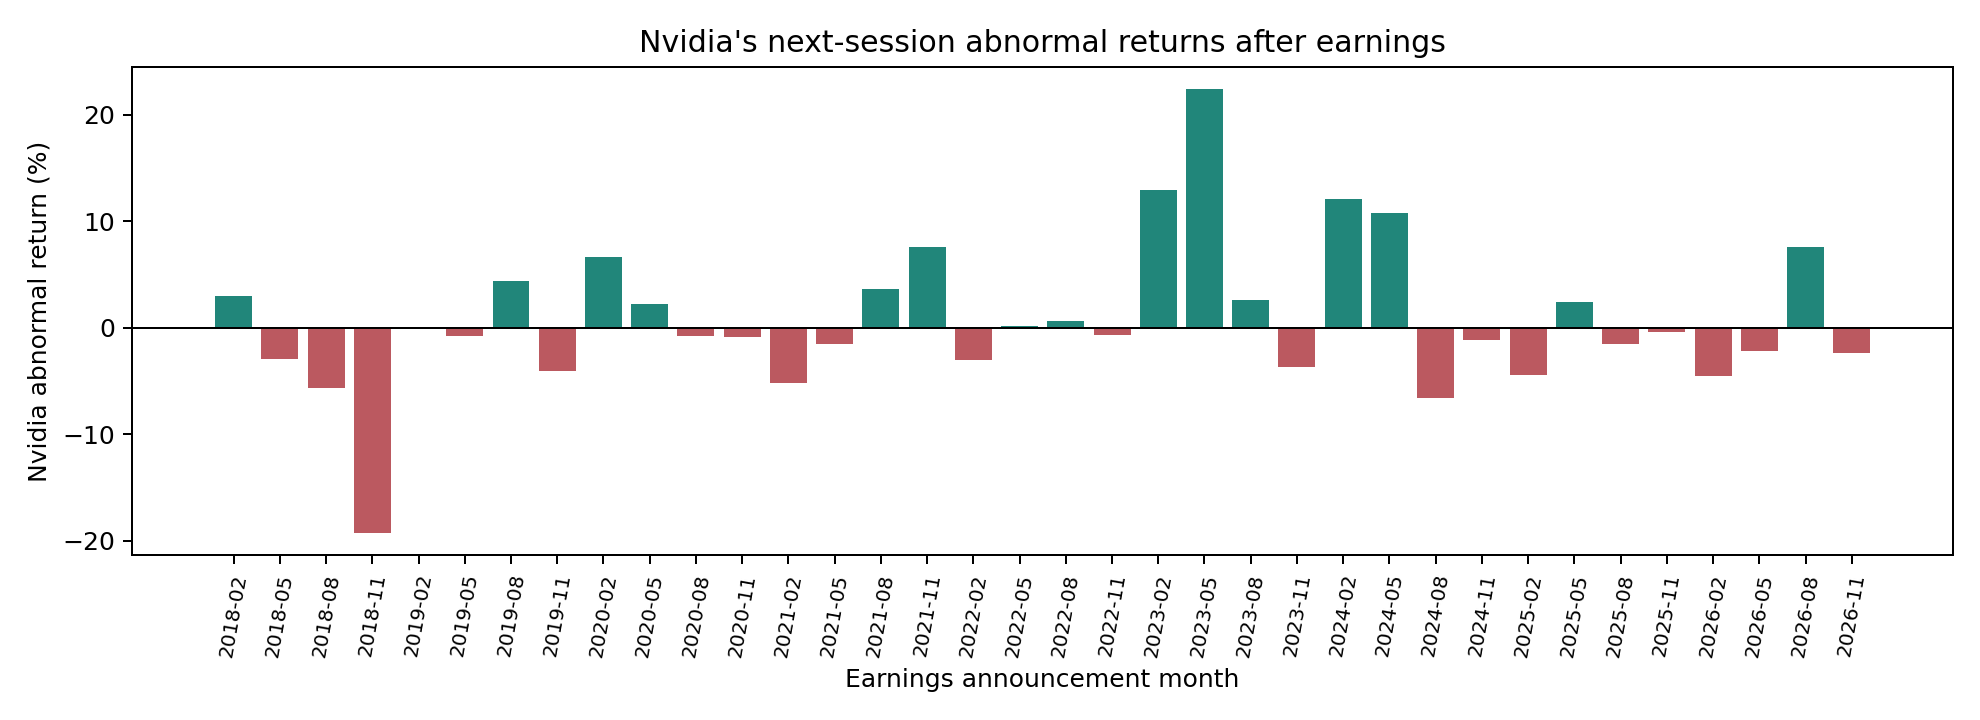

In [8]:
all_us = event_study(us_prices, events, tickers=firm_tickers + ["NVDA"], benchmark="SPY")
if all_us.empty or not all_us.ticker.eq("NVDA").any():
    raise ValueError("Too little price history to estimate Nvidia event reactions. Check data collection.")
all_us.to_csv(PROCESSED / "us_event_returns.csv", index=False)
plot_nvda_reactions(all_us, FIGURES / "01_nvda_earnings_reactions.png")

display(all_us.loc[all_us.ticker.eq("NVDA"),
                   ["announcement_date", "event_date", "abnormal_return"]].tail(8))
nvda_reactions = all_us.loc[all_us.ticker.eq("NVDA")].abnormal_return
print(f"Nvidia: {len(nvda_reactions)} usable events; median absolute AR = {100*nvda_reactions.abs().median():.2f}%")
display(Image(filename=str(FIGURES / "01_nvda_earnings_reactions.png")))

### Interpretation of Nvidia's Earnings Shocks

* **Substantial event-day volatility:** Across all **36 usable earnings announcements** (2018–2026), Nvidia's median absolute next-session abnormal return is **3.00%**, confirming that earnings releases act as major, discrete information shocks rather than routine trading days[cite: 13, 14].
* **Regime shift in reaction magnitude:** The bar chart highlights two distinct eras[cite: 15]. Aside from a sharp **-19%** drop in November 2018 (following the crypto-mining inventory overhang), pre-2023 reactions typically stayed within $\pm 5\%$[cite: 15]. Starting in early 2023—highlighted by massive positive surges in **February 2023 (+13%)**, **May 2023 (+22%)**, **February 2024 (+12%)**, and **May 2024 (+11%)**—Nvidia's earnings became primary market-moving catalysts for the broader AI ecosystem[cite: 15].
* **Recent normalization:** Over the most recent announcements in 2025–2026, reactions have moderated (ranging from **-4.55%** on February 26, 2026 to **+7.55%** on August 27, 2026), reflecting higher baseline expectations priced in ahead of releases[cite: 14, 15].

### H1 - Revealed exposure differs across firms


We now compare each stock's abnormal return to Nvidia's abnormal return on the same announcement. Each slope is estimated with an intercept; stocks with fewer than eight usable events are excluded rather than assigned a slope of zero.

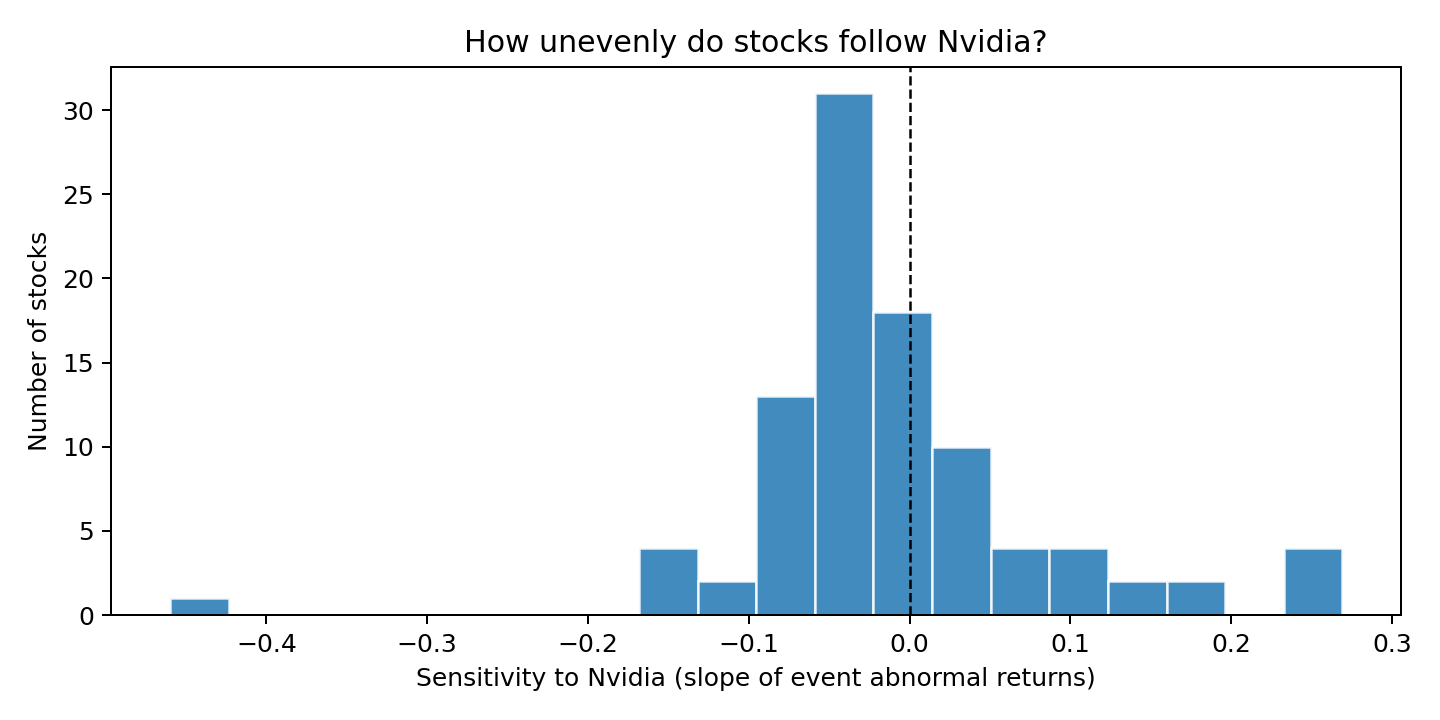

Firms with an estimable slope: 95
Median sensitivity: -0.025
Share with positive sensitivity: 34.7%


,ticker,sensitivity,n_events,r
82,SNPS,0.269100,36,0.532141
7,ALAB,0.251548,8,0.325653
58,MPWR,0.238762,36,0.522430
10,AMD,0.236289,36,0.539904
60,MRVL,0.180129,36,0.480063
15,ASML,0.169484,36,0.578567
21,CDNS,0.140808,36,0.494283
16,AVGO,0.135607,36,0.509815
9,AMAT,0.120456,36,0.273379
63,MU,0.100745,36,0.297016


,ticker,sensitivity,n_events,r
81,SHOP,-0.081781,36,-0.229375
19,BKR,-0.089783,36,-0.329210
85,TMUS,-0.090207,36,-0.468760
80,SBUX,-0.096042,36,-0.538699
31,DDOG,-0.103030,26,-0.210838
30,DASH,-0.134179,21,-0.249912
44,INTC,-0.145304,36,-0.535169
77,RKLB,-0.157024,22,-0.260048
13,APP,-0.162626,20,-0.433364
14,ARM,-0.459913,10,-0.311859


In [9]:
firm_panel = attach_nvda_shocks(all_us)
firm_slopes = sensitivity_by_stock(firm_panel, min_events=settings.min_events_per_slope)
firm_slopes = firm_slopes.sort_values("sensitivity", ascending=False)
if len(firm_slopes) < 5:
    raise ValueError("Insufficient firm slopes. Check histories and event dates.")
firm_slopes.to_csv(PROCESSED / "firm_sensitivity.csv", index=False)
plot_sensitivity_distribution(firm_slopes, FIGURES / "02_firm_sensitivity_histogram.png")
display(Image(filename=str(FIGURES / "02_firm_sensitivity_histogram.png")))

print("Firms with an estimable slope:", len(firm_slopes))
print("Median sensitivity:", round(firm_slopes.sensitivity.median(), 3))
print("Share with positive sensitivity:", f"{100*firm_slopes.sensitivity.gt(0).mean():.1f}%")
display(firm_slopes[["ticker", "sensitivity", "n_events", "r"]].head(10))
display(firm_slopes[["ticker", "sensitivity", "n_events", "r"]].tail(10))

### Interpretation of H1: Cross-Firm Sensitivity Distribution

* **Strong support for H1 (asymmetrical dispersion):** Out of the 100 Nasdaq-100 firms, **95 firms** meet the minimum threshold of 8 earnings observations[cite: 19]. Sensitivities span a wide range from **-0.460** (`ARM`) to **+0.269** (`SNPS`), yet the distribution is tightly centered just below zero with a **median sensitivity of -0.025** and only **34.7%** of firms exhibiting a positive slope[cite: 18, 19]. This confirms **H1**: most Nasdaq-100 companies do not move positively with Nvidia on earnings days, while a concentrated minority responds strongly[cite: 18, 19].
* **Semiconductor and AI infrastructure clustering at the top:** The right tail of the distribution is dominated by chip designers, equipment makers, and AI hardware suppliers—led by **Synopsys (`SNPS`, +0.269, $n=36$)**, **Astera Labs (`ALAB`, +0.252, $n=8$)**, **Monolithic Power Systems (`MPWR`, +0.239, $n=36$)**, **AMD (`AMD`, +0.236, $n=36$)**, **Marvell (`MRVL`, +0.180, $n=36$)**, **ASML (`ASML`, +0.169, $n=36$)**, **Cadence (`CDNS`, +0.141, $n=36$)**, and **Broadcom (`AVGO`, +0.136, $n=36$)**[cite: 19]. Because 9 of the top 10 firms are backed by the full **36 earnings events** (with correlation $r$ between `0.27` and `0.58`), these positive co-movements reflect persistent structural linkages rather than small-sample noise[cite: 19].
* **Caveats on the negative tail:** On the opposite end, legacy chipmaker **Intel (`INTC`, -0.145, $n=36$)** and consumer/telecom names like **Starbucks (`SBUX`, -0.096)** and **T-Mobile (`TMUS`, -0.090)** move inversely to Nvidia shocks—consistent with competitive substitution (`INTC`) or sector rotation out of defensive/consumer stocks into AI hardware on strong Nvidia quarters[cite: 19]. By contrast, extreme slopes among recent listings with fewer events—such as **`ARM` (-0.460, $n=10$)** and **`ALAB` (+0.252, $n=8$)**—should be interpreted cautiously due to their shorter post-IPO estimation samples, and a high slope alone demonstrates statistical co-movement rather than direct causal dependence[cite: 19].

## 4. Do the AI labels predict sensitivity ? (H2)

To test **H2**, we regress each firm's estimated Nvidia sensitivity slope ($b_i$) on observable measures of AI and technology exposure: ICB sector classifications (`technology_label`, `semiconductor_label`), pre-cutoff R&D intensity (`rd_revenue`, computed from SEC filings prior to November 30, 2022 to avoid hindsight bias), and historical market beta (`historical_market_beta`) as a baseline systematic-risk control.

We estimate the cross-sectional OLS model using heteroskedasticity-robust (HC3) standard errors and evaluate only variables with sufficient non-missing coverage across our sample.

In [ ]:
# we estimate pre-november 2022 market betas
beta_controls = market_betas_before_cutoff(us_prices)
label_controls = labels.merge(beta_controls, on="ticker", how="left", validate="one_to_one")

# here we run the cross-sectional OLD regression with HC3 robust standard errors on covariates with sufficient coverage
model, sample, variables = cross_section_regression(firm_slopes, label_controls)
print("Variables with sufficient coverage:", variables)

if model is None:
    print("Insufficient complete, non-collinear observations for a reliable H2 regression.")
    print("Collect SEC facts / issuer holdings, or interpret the sector-only descriptive tables.")
else:
    print(f"H2 regression sample: {int(model.nobs)} firms")
    print(model.summary())
    results = pd.DataFrame({"coefficient": model.params, "robust_se": model.bse,
                            "p_value": model.pvalues})
    results.to_csv(PROCESSED / "h2_coefficients.csv")

# we compute median Nvidia sensitivity grouped by ICB sector across all 95 estimable firms
sector_comparison = firm_slopes.merge(labels[["ticker", "sector"]], on="ticker", how="left")
sector_table = (sector_comparison.groupby("sector", dropna=False)
                .agg(n_firms=("ticker", "count"), median_sensitivity=("sensitivity", "median"))
                .sort_values("median_sensitivity", ascending=False))
display(sector_table)

Variables with sufficient coverage: ['semiconductor_label', 'technology_label', 'rd_revenue', 'historical_market_beta']
H2 regression sample: 57 firms
                            OLS Regression Results                            
Dep. Variable:            sensitivity   R-squared:                       0.292
Model:                            OLS   Adj. R-squared:                  0.237
Method:                 Least Squares   F-statistic:                     5.169
Date:                Sat, 21 Nov 2026   Prob (F-statistic):            0.00139
Time:                        22:06:14   Log-Likelihood:                 66.237
No. Observations:                  57   AIC:                            -122.5
Df Residuals:                      52   BIC:                            -112.3
Df Model:                           4                                         
Covariance Type:                  HC3                                         
                             coef    std err          z    

,n_firms,median_sensitivity
sector,,
Technology,44,0.022656
Basic Materials,1,-0.022844
Consumer Discretionary,15,-0.030526
Health Care,10,-0.039521
Industrials,11,-0.040952
Utilities,4,-0.055514
Consumer Staples,5,-0.055706
Telecommunications,3,-0.075714
Energy,2,-0.077453


### Interpretation of H2: Cross-Sectional Regression and Sector Patterns

* **Overall explanatory power and sample scope:** Across the **57 firms** with complete SEC R&D filings and pre-cutoff market betas, the cross-sectional regression explains **29.2%** of the variation in Nvidia sensitivity ($R^2 = 0.292$, Adjusted $R^2 = 0.237$), and the model is jointly statistically significant ($F = 5.169$, $p = 0.0014$).
* **Broad Technology classification drives sensitivity, while R&D intensity is insignificant:** Conditional on the other covariates, belonging to the **ICB Technology sector** (`technology_label`) is associated with a statistically significant **+0.0749** increase in Nvidia sensitivity ($t = 3.162$, $p = 0.002$). By contrast, the narrower `semiconductor_label` (+0.0594, $p = 0.155$) and SEC R&D-to-revenue ratio `rd_revenue` (+0.0101, $p = 0.890$) carry positive point estimates but are not individually statistically significant—likely because high R&D spending is shared across non-AI sectors (such as pharmaceuticals and hardware) and because semiconductor firms are a subset of the broader Technology classification. Controlling for `historical_market_beta` (-0.0236, $p = 0.626$) confirms that Nvidia sensitivity is not merely capturing high general market beta.
* **Sector-level dispersion confirms the regression:** Looking across all 95 estimable firms grouped by **ICB sector**, **Technology** is the **only sector with a positive median sensitivity (+0.0227 across 44 firms)**. Every other ICB sector exhibits a negative median sensitivity—ranging from **Basic Materials (-0.0228)** and **Consumer Discretionary (-0.0305)** down to **Telecommunications (-0.0757)** and **Energy (-0.0775)**—showing that positive co-movement with Nvidia earnings is concentrated within technology rather than spread across the broader market.
* **Methodological caveats:** These regression estimates represent conditional associations rather than causal effects, are limited to the 57 firms with standardized SEC R&D disclosures, and omit thematic ETF holdings and firm-size controls[cite: 21, 22, 23].

## 5. Did the pattern change after ChatFPT? (H3)

### Descriptive PCA: are stocks moving more together ?

## 6. Gerography of the AI trade (H4)

### Adding country characteristics (World Bank and UN Comtrade)

## 7. Robustness checks

## 8. Synthesis and limits